# Student Scores

In [1]:
# Importing the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:
# Load the data
df = pd.read_csv('student-scores.csv')
df.head(5)

,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76


In [3]:
# Summary Statistics of the dataset
df.describe()

,id,absence_days,weekly_self_study_hours,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.00000,2000.000000,2000.000000
mean,1000.500000,3.665500,17.755500,83.452000,80.332000,81.336500,79.995000,79.58150,81.277500,80.888000
std,577.494589,2.629271,12.129604,13.224906,12.736046,12.539453,12.777895,13.72219,12.027087,11.637705
min,1.000000,0.000000,0.000000,40.000000,50.000000,50.000000,50.000000,30.00000,50.000000,60.000000
25%,500.750000,2.000000,5.000000,77.000000,69.750000,71.000000,69.000000,69.00000,72.000000,71.000000
50%,1000.500000,3.000000,18.000000,87.000000,82.000000,83.000000,81.000000,81.00000,83.000000,81.000000
75%,1500.250000,5.000000,28.000000,93.000000,91.000000,92.000000,91.000000,91.00000,91.000000,91.000000
max,2000.000000,10.000000,50.000000,100.000000,100.000000,100.000000,100.000000,100.00000,99.000000,100.000000


- There are 2000 students sample in the dataset.
- Average absence days is 2.6 while the maxmum is 10 days.
- At least one or more student made the maximum score of 100 in all the subjects except English (99)
- The minimum scores for all the subjects ranges between 30-60 with Biology being the poorest(30) and Geography being the best (60).
- The average weekly study hours is 12.1 with the maximum being 50hrs/week and the minimum being 0.

In [4]:
# Checkiing the datatype for each column
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 17 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   id                          2000 non-null   int64 
 1   first_name                  2000 non-null   object
 2   last_name                   2000 non-null   object
 3   email                       2000 non-null   object
 4   gender                      2000 non-null   object
 5   part_time_job               2000 non-null   bool  
 6   absence_days                2000 non-null   int64 
 7   extracurricular_activities  2000 non-null   bool  
 8   weekly_self_study_hours     2000 non-null   int64 
 9   career_aspiration           2000 non-null   object
 10  math_score                  2000 non-null   int64 
 11  history_score               2000 non-null   int64 
 12  physics_score               2000 non-null   int64 
 13  chemistry_score             2000 non-null   int6

In [5]:
# Checking for duplicates
df.duplicated().sum()

0

In [6]:
# gender distribution in the class
gender_count= df['gender'].value_counts()
gender_count

gender
female    1002
male       998
Name: count, dtype: int64

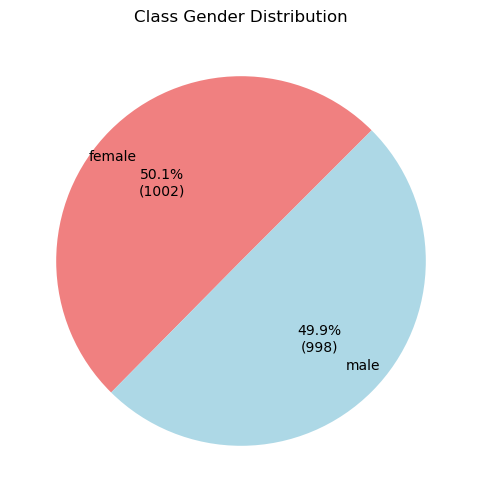

In [7]:
# Visualizing gender distribution in the class population

plt.figure(figsize=(6, 6))
plt.pie(gender_count,
        labels=gender_count.index,
        autopct=lambda p: f'{p:.1f}%\n({round(p*sum(gender_count)/100)})',
        startangle=45,
        colors=['lightcoral', 'lightblue'],
        labeldistance=0.8) 
plt.title('Class Gender Distribution')
plt.show()

In [8]:
# Part time job distribution across the gender
part_time_job_by_gender = df.groupby('gender') ['part_time_job']. value_counts().unstack()


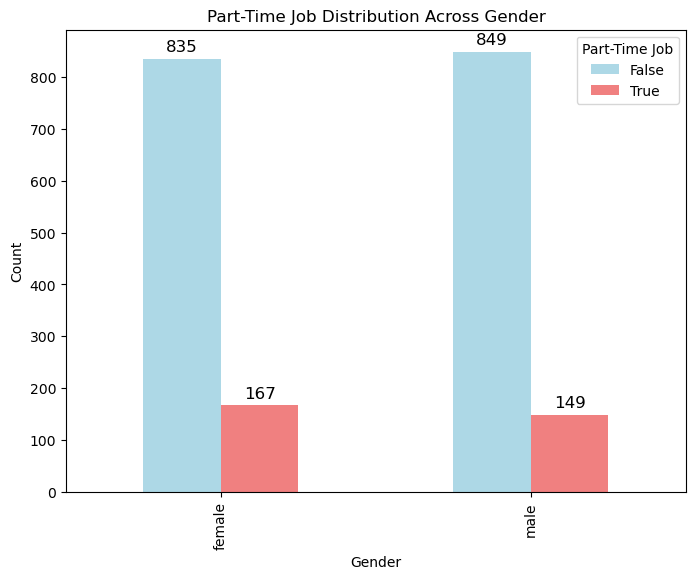

In [9]:
# plot a bar chart to show Part time job distribution by gender
ax = part_time_job_by_gender.plot(kind='bar', figsize=(8, 6), color=['lightblue', 'lightcoral'])

# Add count labels on each bar
for container in ax.containers:
    ax.bar_label(container, fmt='%d', label_type='edge', fontsize=12, padding=3)

plt.xlabel('Gender')
plt.ylabel('Count')
plt.title('Part-Time Job Distribution Across Gender')
plt.legend(title='Part-Time Job', labels=['False', 'True'])

plt.show()

In [10]:
"""Computing cummulative scores"""

#Summing all subjects scores to get the total score
all_subjects = ['math_score', 'history_score', 'physics_score', 'chemistry_score', 'biology_score', 'english_score','geography_score']

# Groupping Science subjects
science_subjects =['math_score', 'physics_score', 'chemistry_score', 'biology_score']

# Grouping Art subjects
art_subjects = ['history_score', 'english_score','geography_score']

# Adding a column for science score
df['science_score'] = df[science_subjects].sum(axis=1)

# Adding a column for art score
df['art_score'] =  df[art_subjects].sum(axis=1)

# Adding a column for total score
df['total_score'] = df[all_subjects].sum(axis=1)

df.head()

,id,first_name,last_name,email,gender,part_time_job,absence_days,extracurricular_activities,weekly_self_study_hours,career_aspiration,math_score,history_score,physics_score,chemistry_score,biology_score,english_score,geography_score,science_score,art_score,total_score
0,1,Paul,Casey,paul.casey.1@gslingacademy.com,male,False,3,False,27,Lawyer,73,81,93,97,63,80,87,326,248,574
1,2,Danielle,Sandoval,danielle.sandoval.2@gslingacademy.com,female,False,2,False,47,Doctor,90,86,96,100,90,88,90,376,264,640
2,3,Tina,Andrews,tina.andrews.3@gslingacademy.com,female,False,9,True,13,Government Officer,81,97,95,96,65,77,94,337,268,605
3,4,Tara,Clark,tara.clark.4@gslingacademy.com,female,False,5,False,3,Artist,71,74,88,80,89,63,86,328,223,551
4,5,Anthony,Campos,anthony.campos.5@gslingacademy.com,male,False,5,False,10,Unknown,84,77,65,65,80,74,76,294,227,521


In [11]:
# getting the numerical columns to compute correlation
numerical_columns = ['absence_days','weekly_self_study_hours','art_score', 'science_score','total_score',
                    'math_score', 'history_score', 'physics_score', 'chemistry_score', 'biology_score', 
                     'english_score','geography_score']


In [12]:
"""Showing the correlation of weekly study hours with each subject"""

# compute pearson's correlation
correlation = df[numerical_columns].corr()['weekly_self_study_hours'].sort_values(ascending=False)
correlation


weekly_self_study_hours    1.000000
total_score                0.501520
science_score              0.425555
math_score                 0.393569
art_score                  0.360916
history_score              0.276231
english_score              0.247796
physics_score              0.202120
chemistry_score            0.201340
biology_score              0.190481
geography_score            0.153622
absence_days              -0.286086
Name: weekly_self_study_hours, dtype: float64

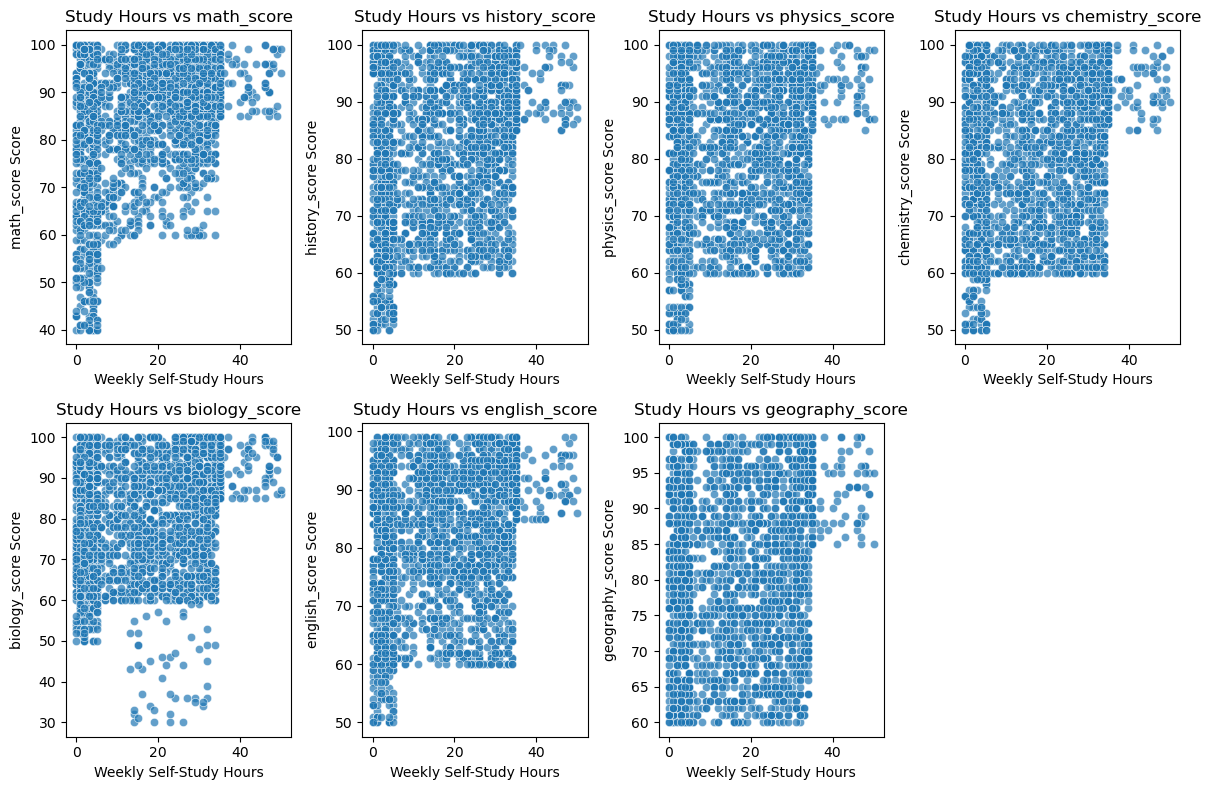

In [13]:
"""Showing the relationship of weekly study hours with each subject"""

# Create scatter plots for each subject
plt.figure(figsize=(12, 8))
for i, subject in enumerate(all_subjects, 1):
    plt.subplot(2, 4, i)  # Arrange plots in a 2x4 grid
    sns.scatterplot(data=df, x='weekly_self_study_hours', y=subject, alpha=0.7)
    plt.title(f'Study Hours vs {subject}')
    plt.xlabel('Weekly Self-Study Hours')
    plt.ylabel(f'{subject} Score')
    
plt.tight_layout()
plt.show()

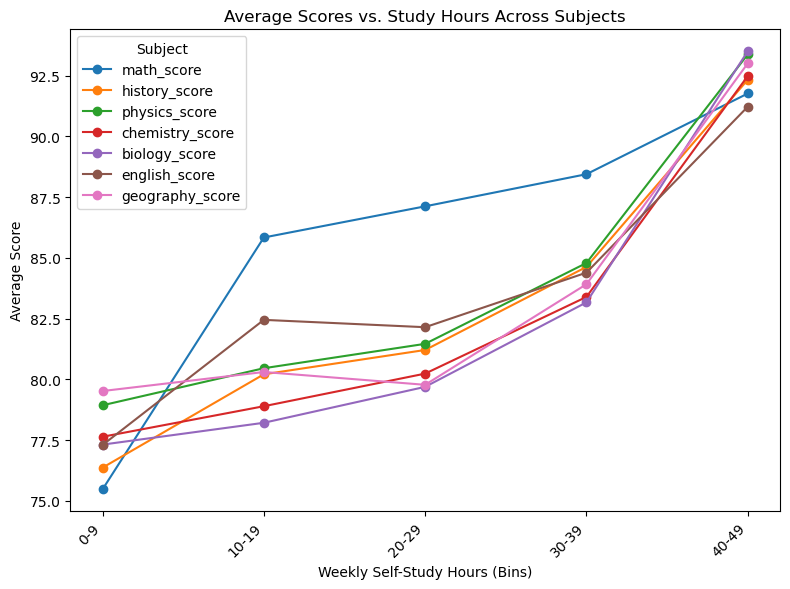

In [16]:
"""Showing the relationship of weekly study hours with each subject"""

# Create bins for study hours
bins = np.arange(0, df['weekly_self_study_hours'].max() + 10, 10)
labels = [f'{i}-{i+9}' for i in bins[:-1]]
df['study_hour_bins'] = pd.cut(df['weekly_self_study_hours'], bins=bins, labels=labels, right=False)

# plot a line chart
plt.figure(figsize=(8, 6))
for i, subject in enumerate(all_subjects):
    # Calculate the mean and standard deviation of scores for each study hour bin
    grouped = df.groupby('study_hour_bins')[subject].agg(['mean', 'std']).reset_index()
    
    plt.plot(grouped['study_hour_bins'], grouped['mean'],
             label=subject, marker='o')


plt.xlabel('Weekly Self-Study Hours')
plt.ylabel('Average Score')
plt.title('Average Scores vs. Study Hours Across Subjects')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

- This chart shows that more self study hours lead to better performance across all subjects.
- Math scores consistently remain the highest across all study hour groups.


In [17]:
"""Impact of Part-Time Job on Overall Performance'"""

# Group by part time job and total score and calculate summary stats for impact of having a partime job on performance
overall_performance = df.groupby('part_time_job')['total_score'].agg(['mean', 'median', 'sum', 'max', 'min']).reset_index()
overall_performance 

,part_time_job,mean,median,sum,max,min
0,False,570.394893,570.0,960545,673,414
1,True,548.037975,552.0,173180,671,414


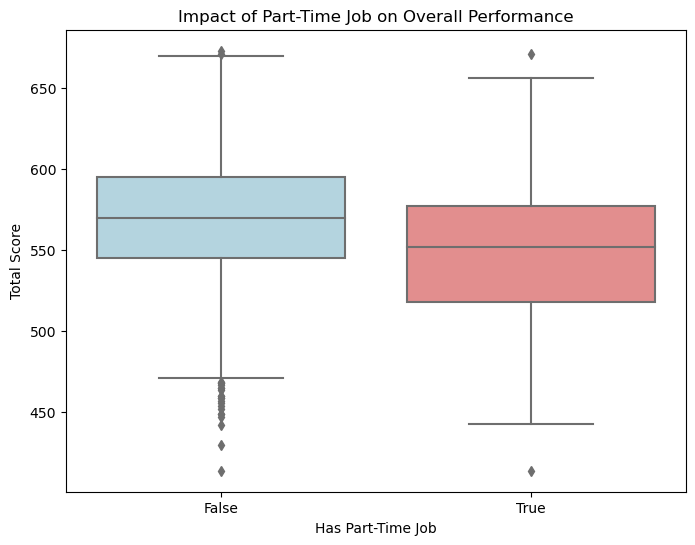

In [18]:
"""Checking the impact of part time job on students' overall performance using a box plot"""

# box plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='part_time_job', y='total_score', palette=['lightblue', 'lightcoral'])
plt.title('Impact of Part-Time Job on Overall Performance')
plt.xlabel('Has Part-Time Job')
plt.ylabel('Total Score')
plt.show()

In [19]:
# Group by extracurricular_activities and total score and calculate summary stats
performance_by_extra = df.groupby('extracurricular_activities')['total_score'].agg(['mean', 'median', 'min', 'max']).reset_index()
performance_by_extra 

,extracurricular_activities,mean,median,min,max
0,False,567.546482,567.0,414,671
1,True,564.193627,567.5,442,673


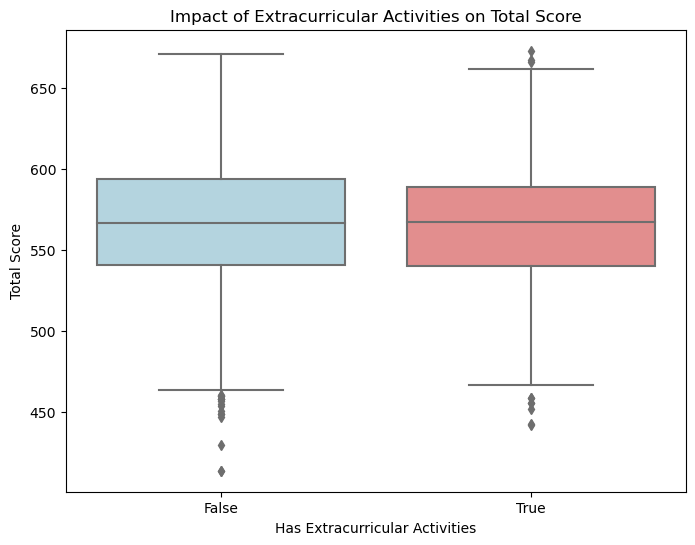

In [20]:

"""Checking the Impact of Extra-Curriculum activities on overall performance"""

# box plot
plt.figure(figsize=(8, 6))
sns.boxplot(data=df, x='extracurricular_activities', y='total_score', palette=['lightblue', 'lightcoral'])
plt.title('Impact of Extracurricular Activities on Total Score')
plt.xlabel('Has Extracurricular Activities')
plt.ylabel('Total Score')
plt.show()

It appears that extra-curricular activity has no negative impact on students academmic performance as the difference in average total score is just 3 marks and median is almost the same for the 2 groups.

In [21]:
 """Checking the immpact of absent days on overall performance"""
    
# Group by absence_days and total score and calculate summary stats
performance_by_absence_days = df.groupby('absence_days')['total_score'].agg(['mean', 'median', 'max','min']).reset_index()
performance_by_absence_days 


,absence_days,mean,median,max,min
0,0,571.317073,569.0,662,489
1,1,571.712610,572.0,670,459
2,2,574.784884,573.0,671,443
3,3,576.205357,575.0,673,442
4,4,567.547739,564.0,656,451
5,5,569.520408,569.0,660,464
6,6,552.470588,557.0,671,414
7,7,555.076923,558.5,662,449
8,8,551.215686,549.0,651,468
9,9,535.160714,543.5,607,449


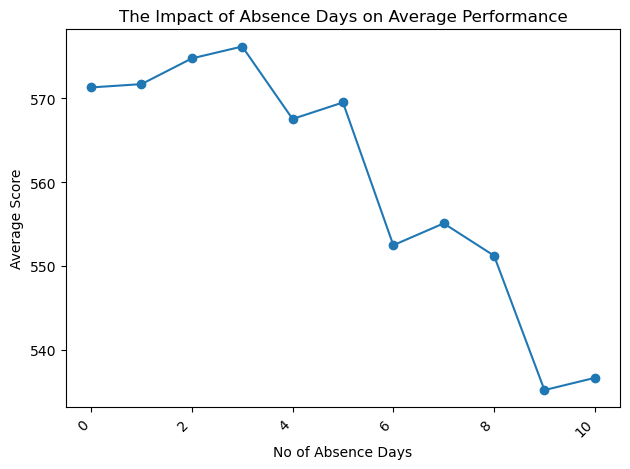

In [22]:
# Plot a line chart to show the impact of absence days on average performance of students

avg_perf_by_absence_days = df.groupby('absence_days')['total_score'].mean().reset_index()

# Plot the line chart
plt.plot(avg_perf_by_absence_days['absence_days'], avg_perf_by_absence_days['total_score'],marker='o') 
plt.xlabel('No of Absence Days')
plt.ylabel('Average Score')
plt.title('The Impact of Absence Days on Average Performance')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

There is an unxpected occurence of a student with 10 absence days achieving a total score(670) higher than those witout absence days. However from the mean score, there is a negative relationshp between absence days and overall performance

In [23]:
"""Impact of Part-Time Jobs on Absence days"""
# Calculate mean, min, and max art scores for both groups
stats = df.groupby('part_time_job')['absence_days'].agg(['mean','median', 'min', 'max', 'count']).reset_index()
stats


,part_time_job,mean,median,min,max,count
0,False,3.430523,3.0,0,10,1684
1,True,4.917722,5.0,0,10,316


In [24]:
# Checking students' performance across each subjects

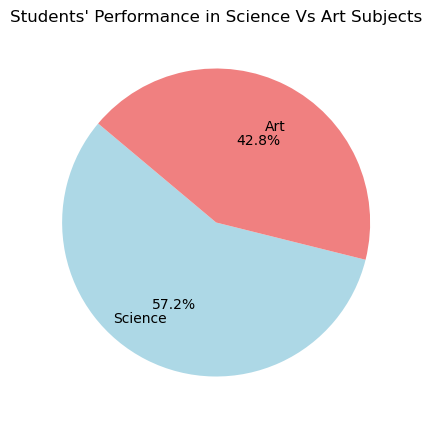

In [25]:
"""Checking students perfomenace across Science and art subjects"""

# Summing Science and Art subject scores
science_total = df['science_score'].sum()
art_total = df['art_score'].sum()

# Pie chart labels and values
labels = ['Science', 'Art']
values = [science_total, art_total]

# Create the pie chart
plt.figure(figsize=(8, 5))
plt.pie(values, labels=labels, autopct='%1.1f%%', colors=['lightblue', 'lightcoral'],labeldistance=0.7, startangle=140)

# Title
plt.title("Students' Performance in Science Vs Art Subjects")

# Show plot
plt.show()


- Students performed better in science subjects than in art subjects

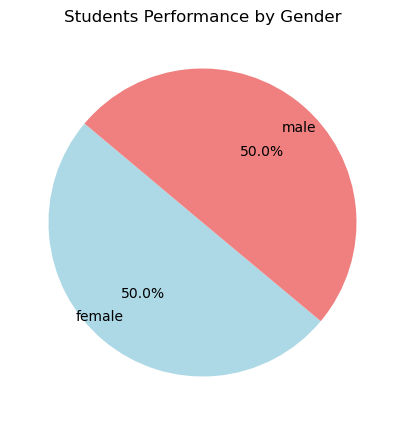

In [26]:
"""Students Performance by Gender"""
performance_by_gender = df.groupby('gender')['total_score'].sum().reset_index()

# Pie chart showing total prices by day type

plt.figure(figsize=(8, 5))

labels = performance_by_gender ['gender']
values = performance_by_gender ['total_score']

plt.pie(values, labels=labels, autopct='%1.1f%%', colors=['lightblue', 'lightcoral'], labeldistance=0.8,startangle=140)
      
# Title
plt.title('Students Performance by Gender')

# Show plot
plt.show()


- Both gender has same level of academic peformance

In [ ]:
# subject with the strongest correlation with overall performance
scores_with_totals = ['math_score', 'history_score', 'physics_score', 'chemistry_score', 'biology_score', 'english_score','geography_score', 'total_score']
# correlation
correlation = df[scores_with_totals].corr()['total_score'].sort_values(ascending=False)
correlation



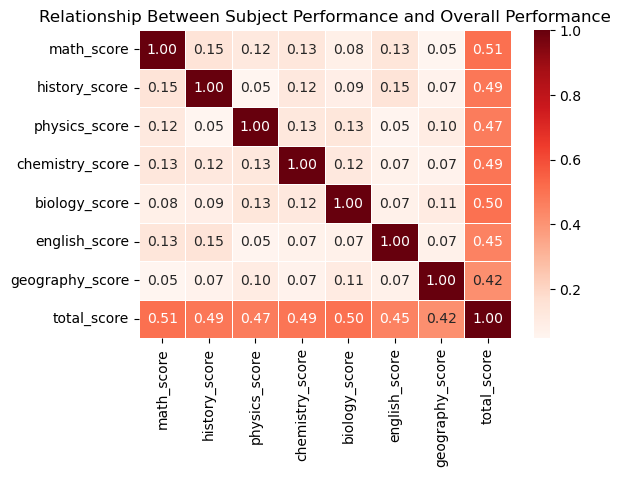

In [28]:
df_scores = df[scores_with_totals].copy() # Create a copy to avoid modifying the original DataFrame

# Calculate the correlation matrix
correlation_matrix = df_scores.corr()

# Visualize the correlation matrix using a heatmap
plt.figure(figsize=(6, 4))
sns.heatmap(correlation_matrix, annot=True, cmap='Reds', fmt=".2f", linewidths=.5)
plt.title('Relationship Between Subject Performance and Overall Performance')
plt.show()

- Mathematics has the strongest positive correllation with the total score, which mean if you do well in mathematics, you are likely to do as well in other subjects too.
- Geography has the list correlation with overall performance
- science oriented subjects show positive correlation to overall performance 

In [29]:
# Do we have students who had part time jobs and also engage in extra curricula activity, what is their overall performance when compare with others

# Create a new column combining part-time job and extracurricular activity
df['Job_Activity'] = df.apply(lambda row: 'Yes' if row['part_time_job'] and row['extracurricular_activities'] else 'No', axis=1)

# Calculate mean, min, and max total scores for both groups
stats = df.groupby('Job_Activity')['total_score'].agg(['mean','median', 'min', 'max']).reset_index()
stats


,Job_Activity,mean,median,min,max
0,No,567.574303,568.0,414,673
1,Yes,544.612903,548.0,443,638


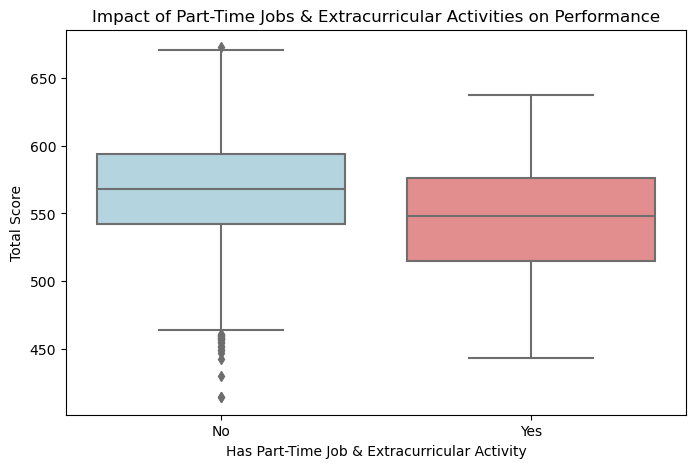

In [30]:
# Box plot to compare total scores 
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Job_Activity', y='total_score', palette=['lightblue', 'lightcoral'])

# Title and labels
plt.title("Impact of Part-Time Jobs & Extracurricular Activities on Performance")
plt.xlabel("Has Part-Time Job & Extracurricular Activity")
plt.ylabel("Total Score")

# Show plot
plt.show()

In [31]:
df['career_aspiration'].unique()

array(['Lawyer', 'Doctor', 'Government Officer', 'Artist', 'Unknown',
       'Software Engineer', 'Teacher', 'Business Owner', 'Scientist',
       'Banker', 'Writer', 'Accountant', 'Designer',
       'Construction Engineer', 'Game Developer', 'Stock Investor',
       'Real Estate Developer'], dtype=object)

In [32]:
"""Impact of Part-Time Jobs & Extracurricular Activities on Performance in Art Subjects"""
# Calculate mean, min, and max art scores for both groups
stats = df.groupby('Job_Activity')['art_score'].agg(['mean','median', 'min', 'max']).reset_index()
stats


,Job_Activity,mean,median,min,max
0,No,242.677503,243.0,168,296
1,Yes,236.870968,241.5,180,279


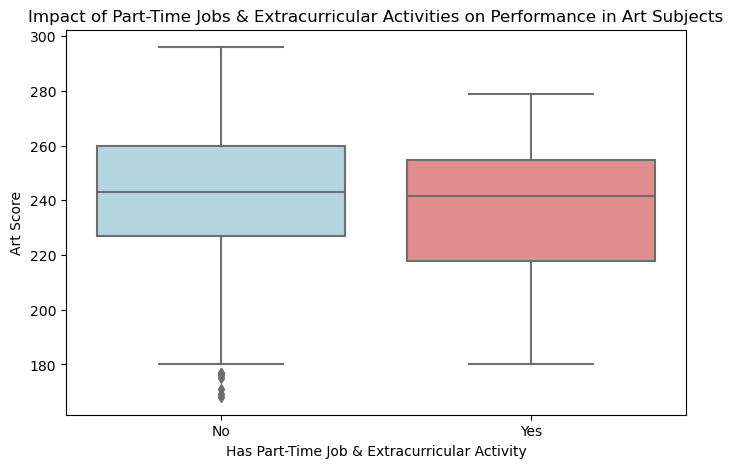

In [33]:
"""Impact of Part-Time Jobs & Extracurricular Activities on Performance in Art Subjects"""

# Box plot 
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Job_Activity', y='art_score', palette=['lightblue', 'lightcoral'])

# Title and labels
plt.title("Impact of Part-Time Jobs & Extracurricular Activities on Performance in Art Subjects")
plt.xlabel("Has Part-Time Job & Extracurricular Activity")
plt.ylabel("Art Score")

# Show plot
plt.show()

In [34]:
"""Impact of Part-Time Jobs & Extracurricular Activities on Performance in Science Subjects"""
# Calculate mean, min, and max art scores for both groups
stats = df.groupby('Job_Activity')['science_score'].agg(['mean','median', 'min', 'max']).reset_index()
stats


,Job_Activity,mean,median,min,max
0,No,324.896801,326.0,217,390
1,Yes,307.741935,312.0,206,383


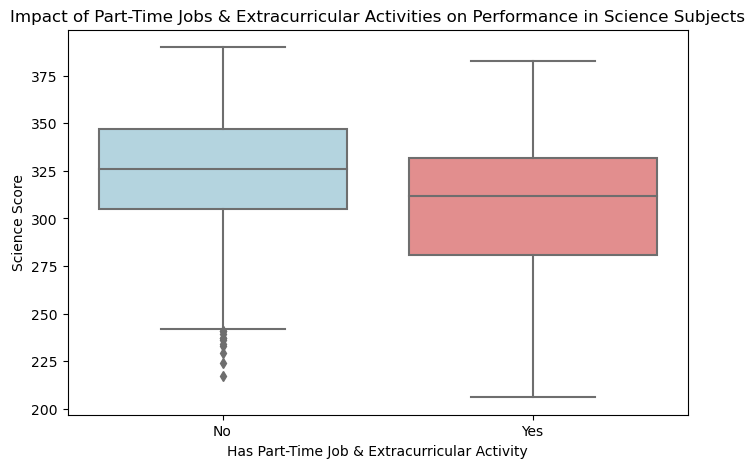

In [35]:
"""Impact of Part-Time Jobs & Extracurricular Activities on Performance in science Subjects"""

# Box plot 
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x='Job_Activity', y='science_score', palette=['lightblue', 'lightcoral'])

# Title and labels
plt.title("Impact of Part-Time Jobs & Extracurricular Activities on Performance in Science Subjects")
plt.xlabel("Has Part-Time Job & Extracurricular Activity")
plt.ylabel("Science Score")

# Show plot
plt.show()

C:\Users\user\AppData\Local\Temp\ipykernel_6404\2523853935.py:5: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='Job_Activity', y='weekly_self_study_hours', data=df, jitter=True, alpha=0.7, palette=['lightblue', 'lightcoral'])


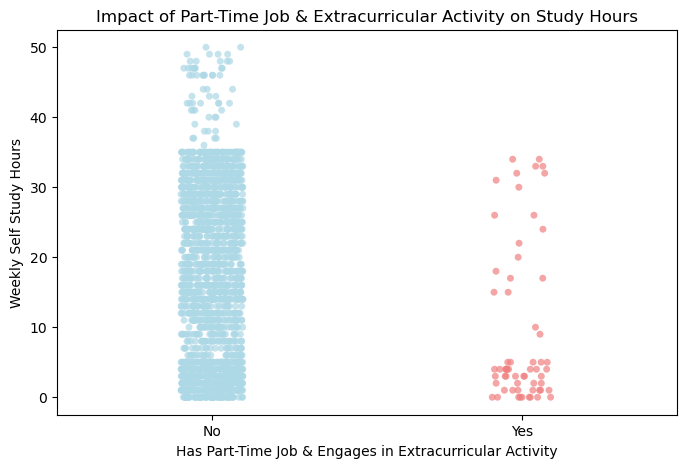

In [36]:
"""The impact of Part Time Jobs and Extracurricular activities on weekly study hours"""

# String plot
plt.figure(figsize=(8, 5))
sns.stripplot(x='Job_Activity', y='weekly_self_study_hours', data=df, jitter=True, alpha=0.7, palette=['lightblue', 'lightcoral'])

plt.title("Impact of Part-Time Job & Extracurricular Activity on Study Hours")
plt.xlabel("Has Part-Time Job & Engages in Extracurricular Activity")
plt.ylabel("Weekly Self Study Hours")

plt.show()

Engaging in extracurricular activities and part time job as a student is time demanding and it neagtively imapcts the time availabe for self study.